<a href="https://colab.research.google.com/github/Mangbunn/nets7052_fa26/blob/main/CompMethHW2GRAPHTOOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sometimes I run everything in this order and it works and sometimes not. so uhhhhhhhhh, enjoy??


In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()



📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

✨🍰✨ Everything looks OK!


In [ ]:
!mamba install -c conda-forge graph-tool


conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache
[+] 0.0s

Pinned packages:

  - python=3.13

Pinned packages:

  - python_abi[version="=3.13",build="*cp313*"]

Pinned packages:

  - cuda-version*.*

Pinned packages:

  - python=3.13


Transaction

  Prefix: /usr/local

  All requested packages already installed


Transaction starting
[+] 0.0s

Transaction finished



In [ ]:
import os
os.environ['LD_LIBRARY_PATH'] = '/usr/local/lib:' + os.environ.get('LD_LIBRARY_PATH', '')


In [ ]:
import graph_tool.all as gt

# Test to make sure it loads successfully
g = gt.Graph()
print("Success! graph-tool version:", gt.__version__)


Success! graph-tool version: 3.9


In [ ]:
!rm -f misc-3elp.zip misc-3elp.php.zip 3elt.zip
!wget -O 3elt.zip https://nrvis.com/download/data/misc/3elt.zip
!file 3elt.zip
!unzip -o 3elt.zip
!ls

--2026-10-15 20:45:15--  https://nrvis.com/download/data/misc/3elt.zip
Resolving nrvis.com (nrvis.com)... 74.208.236.139, 2607:f1c0:100f:f000::200
Connecting to nrvis.com (nrvis.com)|74.208.236.139|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 39255 (38K) [application/zip]
Saving to: ‘3elt.zip’

3elt.zip            100%[===================>]  38.33K  --.-KB/s    in 0.06s   

2026-10-15 20:45:16 (602 KB/s) - ‘3elt.zip’ saved [39255/39255]

3elt.zip: Zip archive data, at least v2.0 to extract, compression method=deflate
Archive:  3elt.zip
  inflating: 3elt.mtx                
  inflating: readme.html             
3elt.mtx  3elt.zip  condacolab_install.log  readme.html  sample_data


In [ ]:
import scipy.io, networkx as nx, numpy as np
A = scipy.io.mmread('3elt.mtx')
G = nx.from_scipy_sparse_array(A)
deg = np.array([d for _, d in G.degree()])
print(len(deg), deg.min(), deg.max())   # expect ~4.7K nodes, max degree 9

/tmp/ipykernel_5217/1405731943.py:2: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  A = scipy.io.mmread('3elt.mtx')


4720 3 9


graph-tool communities: 46


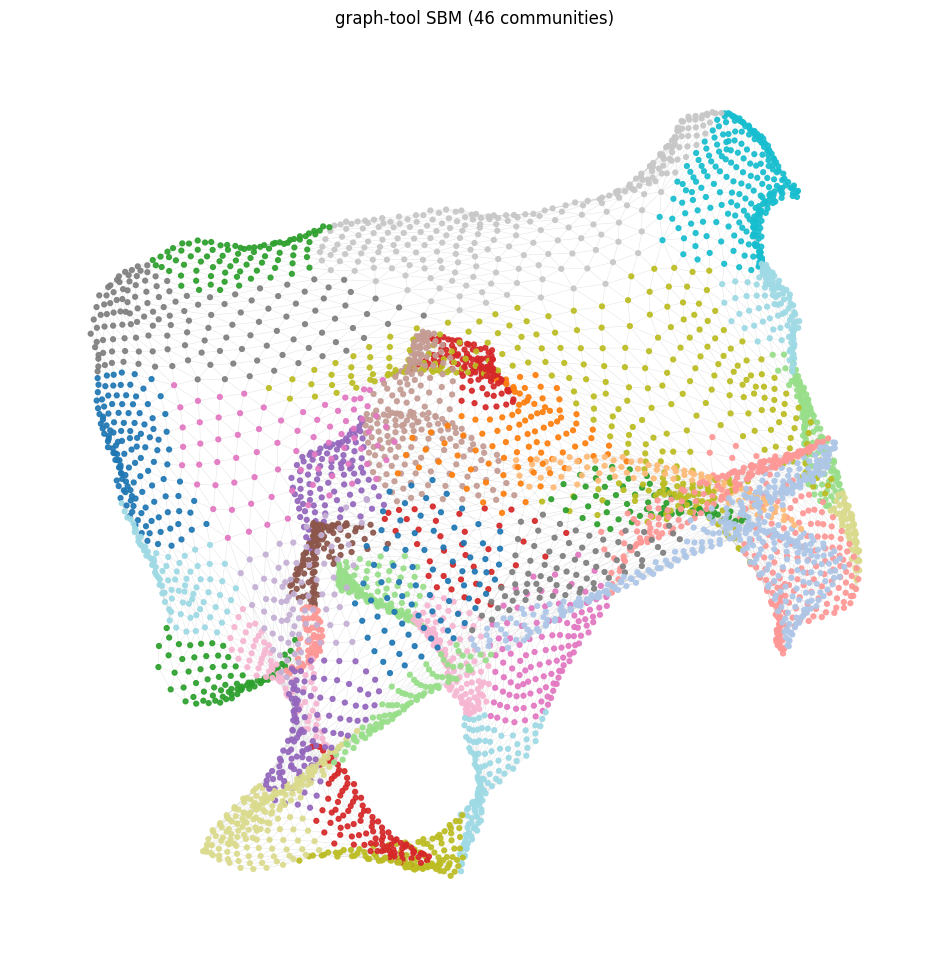

In [ ]:
import graph_tool.all as gt
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib import cm




pos = nx.spring_layout(G, k=0.3, iterations=100, seed=42)

def draw_partition(G, pos, part, title, fname):
    fig, ax = plt.subplots(figsize=(12, 12))
    nx.draw_networkx_edges(G, pos, alpha=0.2, width=0.4, edge_color="gray", ax=ax)
    nx.draw_networkx_nodes(G, pos, node_size=12,
                           node_color=[part[n] for n in G.nodes()],
                           cmap=cm.tab20, alpha=0.9, ax=ax)
    ax.set_title(title); ax.axis("off")
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()


def nx_to_gt(G):
  g=gt.Graph(directed = False)
  g.add_vertex(G.number_of_nodes())
  g.add_edge_list(list(G.edges()))
  return g

def gt_partition(G, seed = 42):
  gt.seed_rng(seed); np.random.seed(seed)
  g = nx_to_gt(G)
  state = gt.minimize_blockmodel_dl(g)
  b = state.get_blocks()
  part = {int(v): int(b[v]) for v in g.vertices()}
  return part



part_b = gt_partition(G)
print("graph-tool communities:", len(set(part_b.values())))

draw_partition(G, pos, part_b,
               f"graph-tool SBM ({len(set(part_b.values()))} communities)",
               "graphtool_3elt.png")

Number of communities: 7
Modularity: 0.8041


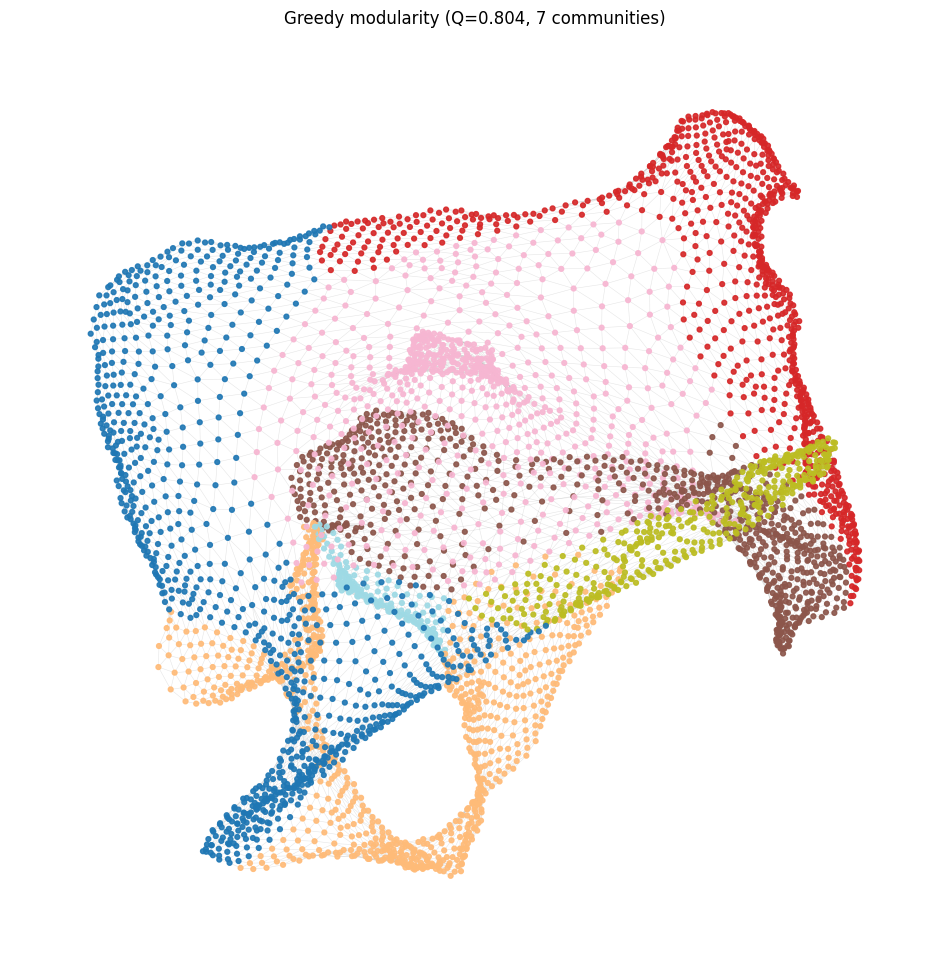

In [ ]:

from networkx.algorithms.community import greedy_modularity_communities, modularity

# make sure node ids are 0..N-1 (and take the largest component if needed)
G = nx.convert_node_labels_to_integers(G)

# --- algorithm ---
communities_a = greedy_modularity_communities(G)
part_a = {node: cid for cid, comm in enumerate(communities_a) for node in comm}

# --- results ---
Q_a = modularity(G, communities_a)
print(f"Number of communities: {len(communities_a)}")
print(f"Modularity: {Q_a:.4f}")

# --- layout: compute ONCE, reuse for (b)


draw_partition(G, pos, part_a, f"Greedy modularity (Q={Q_a:.3f}, {len(communities_a)} communities)",
               "greedy_3elt.png")

In [ ]:
G_rand = G.copy()
m = G_rand.number_of_edges()
nx.double_edge_swap(G_rand, nswap=10*m, max_tries=100*m, seed=42)

assert dict(G.degree()) == dict(G_rand.degree())   # sanity check

comm_c = greedy_modularity_communities(G_rand)
part_c_greedy = {n: i for i, c in enumerate(comm_c) for n in c}
part_c_gt = gt_partition(G_rand)

print("Randomized modularity (greedy):", modularity(G_rand, comm_c))

Randomized modularity (greedy): 0.3930348227396151


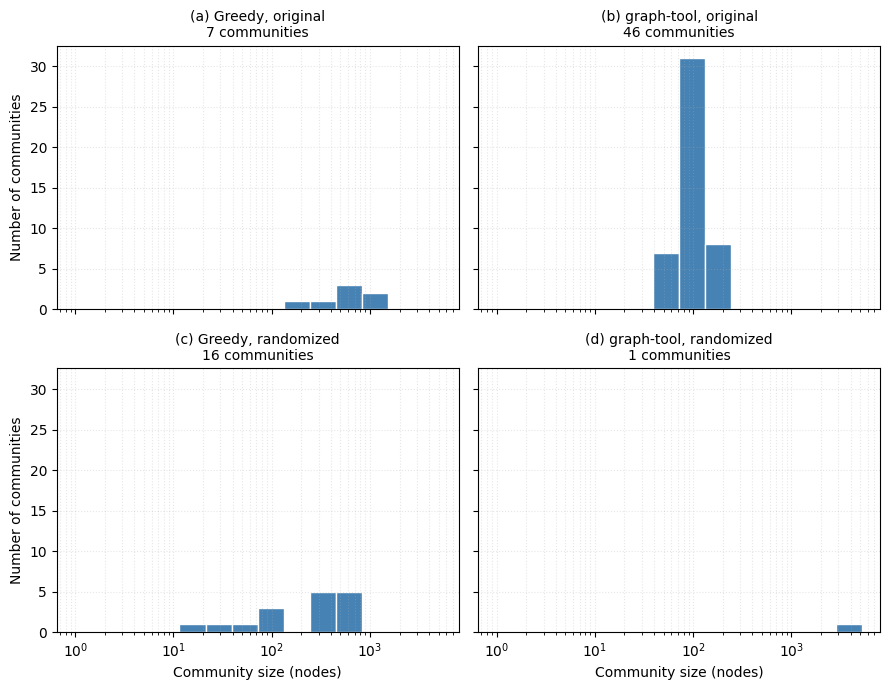

In [ ]:
partitions = {
    "(a) Greedy, original":      part_a,
    "(b) graph-tool, original":  part_b,
    "(c) Greedy, randomized":    part_c_greedy,
    "(d) graph-tool, randomized": part_c_gt,
}

def sizes(part):
    return np.array(list(
        __import__("collections").Counter(part.values()).values()))

all_sizes = [sizes(p) for p in partitions.values()]
smax = max(s.max() for s in all_sizes)
bins = np.logspace(0, np.log10(smax * 1.1), 15)   # shared log bins
#bins = np.linspace(0, smax, 15)

fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for ax, (name, part), s in zip(axes.flat, partitions.items(), all_sizes):
    ax.hist(s, bins=bins, color="steelblue", edgecolor="white")
    ax.set_xscale("log"); ax.set_yscale("linear")
    ax.set_title(f"{name}\n{len(s)} communities", fontsize=10)
    ax.grid(alpha=0.3, which="both", linestyle=":")
for ax in axes[1]:  ax.set_xlabel("Community size (nodes)")
for ax in axes[:, 0]: ax.set_ylabel("Number of communities")
fig.tight_layout()
fig.savefig("community_size_dist.pdf", bbox_inches="tight")
plt.show()

In [ ]:
from collections import defaultdict
import json

def Q_of(G, part):
    groups = defaultdict(set)
    for n, c in part.items():
        groups[c].add(n)
    return nx.community.modularity(G, groups.values())

for name, g_, p in [("(a) greedy, orig", G, part_a),
                    ("(b) graph-tool, orig", G, part_b),
                    ("(c) greedy, rand", G_rand, part_c_greedy),
                    ("(d) graph-tool, rand", G_rand, part_c_gt)]:
    print(f"{name:22s} K={len(set(p.values())):3d}  Q={Q_of(g_, p):.4f}")

# save in case the kernel restarts again
json.dump({k: {str(n): c for n, c in p.items()} for k, p in partitions.items()},
          open("partitions.json", "w"))

(a) greedy, orig       K=  7  Q=0.8041
(b) graph-tool, orig   K= 44  Q=0.8875
(c) greedy, rand       K= 16  Q=0.3930
(d) graph-tool, rand   K=  1  Q=0.0000
